# Diskusi 4 – Regresi Berganda
**STIK4121 – Metode Statistik**


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.precision", 4)
plt.style.use("seaborn-v0_8-whitegrid") if "seaborn-v0_8-whitegrid" in plt.style.available else plt.style.use("default")

data = pd.DataFrame(
    {
        "X1": [3, 4, 4, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9, 10, 10],
        "X2": [8, 10, 12, 13, 15, 16, 18, 20, 21, 23, 24, 26, 28, 30, 32],
        "X3": [60, 62, 65, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90],
        "Y":  [58, 61, 64, 67, 69, 71, 73, 76, 78, 81, 83, 85, 87, 90, 92],
    },
    index=pd.RangeIndex(1, 16, name="No")
)

data

,X1,X2,X3,Y
No,,,,
1,3,8,60,58
2,4,10,62,61
3,4,12,65,64
4,5,13,68,67
5,5,15,70,69
6,6,16,72,71
7,6,18,74,73
8,7,20,76,76
9,7,21,78,78


In [ ]:
def ols(X, y):

    # 1. Konversi data dan bentuk matriks desain A = [1 | X]
    X_mat = np.asarray(X, dtype=float)
    y_vec = np.asarray(y, dtype=float)
    n = len(y_vec)
    A = np.c_[np.ones(n), X_mat]
    p = A.shape[1]                       # Jumlah parameter: k prediktor + 1 intercept
    df_resid = n - p # Derajat bebas galat (residual)

    # 2. Estimasi koefisien OLS: b = (A^T A)^(-1) A^T y
    b = np.linalg.solve(A.T @ A, A.T @ y_vec)
    yhat = A @ b
    resid = y_vec - yhat

    # 3. Jumlah Kuadrat (Sum of Squares)
    sst = np.sum((y_vec - y_vec.mean()) ** 2)   # Total Sum of Squares
    sse = np.sum(resid ** 2)                    # Error Sum of Squares
    ssr = sst - sse                             # Regression Sum of Squares

    # 4 (MSE) & Matriks Kovarians Koefisien
    mse = sse / df_resid
    cov = mse * np.linalg.inv(A.T @ A)
    se = np.sqrt(np.diag(cov))

    # 5. Uji Signifikansi Parsial (Uji t)
    t_stat = b / se
    p_val_t = 2 * stats.t.sf(np.abs(t_stat), df=df_resid)

    # 6. Koefisien Determinasi (R² & Adjusted R²)
    r2 = 1.0 - (sse / sst)
    adj_r2 = 1.0 - (1.0 - r2) * (n - 1) / df_resid

    # 7. Uji Signifikansi Simultan (Uji F ANOVA)
    df_reg = p - 1
    f_stat = (ssr / df_reg) / mse
    p_val_f = stats.f.sf(f_stat, dfn=df_reg, dfd=df_resid)

    return {
        "b": b,
        "se": se,
        "t": t_stat,
        "p": p_val_t,
        "r2": r2,
        "adj": adj_r2,
        "F": f_stat,
        "pF": p_val_f,
        "sse": sse,
        "sst": sst,
        "ssr": ssr,
        "mse": mse,
        "df": df_resid,
        "n": n,
        "yhat": yhat,
        "resid": resid,
        "cov": cov,
        "A": A,
    }



# Variabel respons (y) dan kamus label variabel
y = data["Y"].values
nama = {
    "Y": "Nilai akhir",
    "X1": "Jam belajar mandiri",
    "X2": "Jumlah akses tuton",
    "X3": "Nilai tugas tutorial",
}

## No. 1 – Variabel respons
Variabel respons adalah variabel yang dijelaskan atau diprediksi, yaitu **Nilai akhir (Y)** mahasiswa pada mata kuliah Metode Statistik.

## No. 2 – Variabel prediktor
- **X₁** = Jam belajar mandiri (jam/minggu)
- **X₂** = Jumlah akses tuton (kali, LMS)
- **X₃** = Nilai tugas tutorial

## No. 3 – Mengapa regresi berganda, bukan sederhana?
- Tutor menduga nilai akhir dipengaruhi **lebih dari satu faktor** sekaligus, bukan hanya jam belajar, tetapi juga keaktifan tuton dan kualitas tugas.
- Regresi sederhana hanya memuat satu X, sehingga pengaruh X lain terserap ke koefisiennya. Contoh dari data ini: slope Y terhadap X₁ saja adalah **4,70**, padahal di regresi berganda koefisien X₁ hanya **0,64** (lihat no. 9).
- Regresi berganda memisahkan pengaruh tiap prediktor dengan mengendalikan prediktor lainnya (*ceteris paribus*).
- Model berganda menjelaskan variasi Y lebih lengkap dan prediksinya lebih akurat.

## No. 4 – Pola data dan korelasi

=== Matriks Korelasi Pearson ===
         Y      X1      X2      X3
Y   1.0000  0.9944  0.9977  0.9993
X1  0.9944  1.0000  0.9918  0.9924
X2  0.9977  0.9918  1.0000  0.9964
X3  0.9993  0.9924  0.9964  1.0000


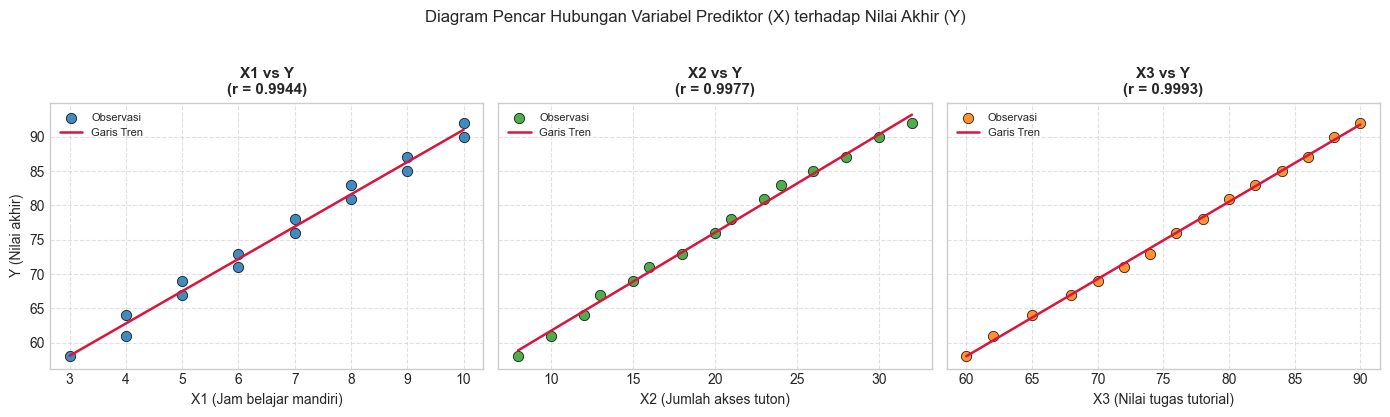


=== Uji Signifikansi Korelasi terhadap Y ===
                 Variabel  Koef. Korelasi (r)  p-value Signifikansi (α=0.05)
 X1 (Jam belajar mandiri)              0.9944 4.56e-14 Signifikan (p < 0.05)
  X2 (Jumlah akses tuton)              0.9977 1.43e-16 Signifikan (p < 0.05)
X3 (Nilai tugas tutorial)              0.9993 7.69e-20 Signifikan (p < 0.05)


In [6]:
# 1. Matriks Korelasi Antar-Variabel
corr = data[["Y", "X1", "X2", "X3"]].corr()
print("=== Matriks Korelasi Pearson ===")
display(corr) if "display" in globals() else print(corr)

# 2. Visualisasi Diagram Pencar (Scatter Plot) dan Garis Tren
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
warna_titik = ["#1f77b4", "#2ca02c", "#ff7f0e"]

for ax, k, warna in zip(axes, ["X1", "X2", "X3"], warna_titik):
    x_val = data[k]
    y_val = data["Y"]
    
    # Titik data observasi
    ax.scatter(
        x_val, y_val, 
        color=warna, s=55, alpha=0.85, 
        edgecolors="black", linewidth=0.6, 
        label="Observasi"
    )
    
    # Garis tren linier sederhana
    slope, intercept = np.polyfit(x_val, y_val, deg=1)
    x_line = np.linspace(x_val.min(), x_val.max(), 50)
    ax.plot(x_line, intercept + slope * x_line, color="crimson", linewidth=1.8, label="Garis Tren")
    
    ax.set_title(f"{k} vs Y\n(r = {corr.loc['Y', k]:.4f})", fontsize=11, fontweight="bold")
    ax.set_xlabel(f"{k} ({nama[k]})", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="upper left", fontsize=8)

axes[0].set_ylabel(f"Y ({nama['Y']})", fontsize=10)
plt.suptitle("Diagram Pencar Hubungan Variabel Prediktor (X) terhadap Nilai Akhir (Y)", fontsize=12, y=1.03)
plt.tight_layout()
plt.show()

# 3. Uji Signifikansi Korelasi Pearson (H0: ρ = 0 vs H1: ρ ≠ 0)
uji_korelasi = []
for k in ["X1", "X2", "X3"]:
    r_val, p_val = stats.pearsonr(data[k], data["Y"])
    uji_korelasi.append({
        "Variabel": f"{k} ({nama[k]})",
        "Koef. Korelasi (r)": r_val,
        "p-value": f"{p_val:.2e}",
        "Signifikansi (α=0.05)": "Signifikan (p < 0.05)" if p_val < 0.05 else "Tidak Signifikan",
    })

df_uji_korelasi = pd.DataFrame(uji_korelasi)
print("\n=== Uji Signifikansi Korelasi terhadap Y ===")
display(df_uji_korelasi) if "display" in globals() else print(df_uji_korelasi.to_string(index=False))

**Kesimpulan:** ketiganya berkorelasi positif sangat kuat dan signifikan dengan Y (r > 0,99). Mahasiswa dengan jam belajar, akses tuton, dan nilai tugas lebih tinggi cenderung memiliki nilai akhir lebih tinggi.

## No. 5 – Estimasi a, b₁, b₂, b₃
Metode kuadrat terkecil (OLS): $\hat\beta=(X^TX)^{-1}X^Ty$.

In [7]:
# 1. Pemasangan Model OLS Berganda
X = data[["X1", "X2", "X3"]].values
m = ols(X, y)

# 2. Tabel Estimasi Koefisien Parameter
tab_koef = pd.DataFrame(
    {
        "Koefisien (b)": m["b"],
        "Std. Error (SE)": m["se"],
        "t-hitung": m["t"],
        "p-value": m["p"],
        "Signifikan (α=0.05)": ["Ya (p < 0.05)" if p < 0.05 else "Tidak (p ≥ 0.05)" for p in m["p"]],
    },
    index=["a (Konstanta)", "b1 (X1 - Jam Mandiri)", "b2 (X2 - Akses Tuton)", "b3 (X3 - Nilai Tugas)"]
)

print("=== Tabel Estimasi Koefisien Regresi ===")
display(tab_koef) if "display" in globals() else print(tab_koef)

# Persamaan Matematis Garis Regresi
a, b1, b2, b3 = m["b"]
print(f"\nPersamaan Regresi Berganda:")
print(f"Ŷ = {a:.4f} + {b1:.4f}*X1 + {b2:.4f}*X2 + {b3:.4f}*X3")

# Verifikasi numerik silang dengan np.linalg.lstsq
chk = np.linalg.lstsq(np.c_[np.ones(15), X], y, rcond=None)[0]
print(f"\nVerifikasi numerik cocok dengan lstsq: {np.allclose(chk, m['b'])}")

# 3. Ringkasan Kebaikan Suai Model (Goodness of Fit)
print(f"\nEvaluasi Model:")
print(f"• R² (Koef. Determinasi) : {m['r2']:.4f} ({m['r2']*100:.2f}% variasi Y dijelaskan oleh model)")
print(f"• Adjusted R²           : {m['adj']:.4f}")
print(f"• F-hitung              : {m['F']:.2f} (db = 3, {m['df']}) | p-value = {m['pF']:.2e}")

# 4. Tabel Analisis Ragam (ANOVA)
anova = pd.DataFrame(
    {
        "Jumlah Kuadrat (SS)": [m["ssr"], m["sse"], m["sst"]],
        "Derajat Bebas (db)": [3, m["df"], 14],
        "Kuadrat Tengah (MS)": [m["ssr"] / 3, m["mse"], np.nan],
        "F-hitung": [m["F"], np.nan, np.nan],
        "p-value": [m["pF"], np.nan, np.nan],
    },
    index=["Regresi", "Galat / Residual", "Total"]
)

print("\n=== Tabel Analisis Ragam (ANOVA) ===")
display(anova) if "display" in globals() else print(anova)

=== Tabel Estimasi Koefisien Regresi ===
                       Koefisien (b)  Std. Error (SE)  t-hitung     p-value  \
a (Konstanta)                10.2406           5.4897    1.8654  8.9001e-02   
b1 (X1 - Jam Mandiri)         0.6354           0.3065    2.0733  6.2421e-02   
b2 (X2 - Akses Tuton)         0.3208           0.1351    2.3740  3.6889e-02   
b3 (X3 - Nilai Tugas)         0.7245           0.1101    6.5786  3.9778e-05   

                      Signifikan (α=0.05)  
a (Konstanta)            Tidak (p ≥ 0.05)  
b1 (X1 - Jam Mandiri)    Tidak (p ≥ 0.05)  
b2 (X2 - Akses Tuton)       Ya (p < 0.05)  
b3 (X3 - Nilai Tugas)       Ya (p < 0.05)  

Persamaan Regresi Berganda:
Ŷ = 10.2406 + 0.6354*X1 + 0.3208*X2 + 0.7245*X3

Verifikasi numerik cocok dengan lstsq: True

Evaluasi Model:
• R² (Koef. Determinasi) : 0.9994 (99.94% variasi Y dijelaskan oleh model)
• Adjusted R²           : 0.9992
• F-hitung              : 5710.80 (db = 3, 11) | p-value = 7.77e-18

=== Tabel Analisis Ragam (A

## No. 6 – Interpretasi koefisien
Model: **Ŷ = 10,2406 + 0,6354 X₁ + 0,3208 X₂ + 0,7245 X₃** (nilai dari no. 5).

- **a = 10,24** – nilai akhir prediksi bila X₁ = X₂ = X₃ = 0. Ini hanya titik potong matematis dan tidak bermakna praktis, karena nilai 0 berada di luar rentang data.
- **b₁ = 0,635** – setiap tambahan 1 jam belajar mandiri per minggu menaikkan nilai akhir rata-rata sekitar 0,64 poin, dengan akses tuton dan nilai tugas tetap.
- **b₂ = 0,321** – setiap tambahan 1 kali akses tuton menaikkan nilai akhir rata-rata sekitar 0,32 poin, dengan jam belajar dan nilai tugas tetap.
- **b₃ = 0,724** – setiap kenaikan 1 poin nilai tugas menaikkan nilai akhir rata-rata sekitar 0,72 poin, dengan jam belajar dan akses tuton tetap.

Ketiga koefisien positif, sesuai pola data di no. 4.

## No. 7 – Prediksi: X₁ = 6, X₂ = 18, X₃ = 75

In [8]:
# 1. Nilai Prediktor Baru: X1 = 6 jam, X2 = 18 kali, X3 = 75 skor
x0 = np.array([1.0, 6.0, 18.0, 75.0])    # Disertai konstanta 1 di awal

# Prediksi titik (Point Prediction)
yhat0 = x0 @ m["b"]

# 2. Standar Error Prediksi:
#    - se_mean: SE untuk nilai rata-rata populasi E[Y|X0]  --> sqrt(x0 @ Cov @ x0)
#    - se_pred: SE untuk satu nilai individu baru Y0        --> sqrt(MSE + x0 @ Cov @ x0)
t_kritis = stats.t.ppf(0.975, df=m["df"])
se_mean = np.sqrt(x0 @ m["cov"] @ x0)
se_pred = np.sqrt(m["mse"] + x0 @ m["cov"] @ x0)

# Rentang interval estimasi 95%
ci_mean = [yhat0 - t_kritis * se_mean, yhat0 + t_kritis * se_mean]
pi_indiv = [yhat0 - t_kritis * se_pred, yhat0 + t_kritis * se_pred]

print("=== Hasil Prediksi Nilai Akhir (No. 7) ===")
print(f"Input Data   : X1 = 6 jam, X2 = 18 kali, X3 = 75")
print(f"Substitusi   : Ŷ = {a:.4f} + {b1:.4f}(6) + {b2:.4f}(18) + {b3:.4f}(75)")
print(f"Prediksi Titik (Ŷ₀)               : {yhat0:.2f}")
print(f"Selang Kepercayaan 95% (Rata-rata): [{ci_mean[0]:.2f}, {ci_mean[1]:.2f}] (margin: ±{t_kritis*se_mean:.2f})")
print(f"Selang Prediksi 95% (Individu)    : [{pi_indiv[0]:.2f}, {pi_indiv[1]:.2f}] (margin: ±{t_kritis*se_pred:.2f})")

=== Hasil Prediksi Nilai Akhir (No. 7) ===
Input Data   : X1 = 6 jam, X2 = 18 kali, X3 = 75
Substitusi   : Ŷ = 10.2406 + 0.6354(6) + 0.3208(18) + 0.7245(75)
Prediksi Titik (Ŷ₀)               : 74.16
Selang Kepercayaan 95% (Rata-rata): [73.68, 74.64] (margin: ±0.48)
Selang Prediksi 95% (Individu)    : [73.34, 74.99] (margin: ±0.82)


## No. 8 – Multikolinearitas
Bukti: (1) korelasi antar-X, (2) VIF, (3) condition number, (4) ketidakstabilan koefisien (leave-one-out) dan standard error besar.

In [ ]:
# ==============================================================================
# (1) Korelasi Antar-Prediktor
# ==============================================================================
corr_x = data[["X1", "X2", "X3"]].corr()
print("=== 1. Matriks Korelasi Antar-Prediktor ===")
display(corr_x) if "display" in globals() else print(corr_x.round(4))

# ==============================================================================
# (2) Variance Inflation Factor (VIF)
#     Rumus: VIF_j = 1 / (1 - R²_j)
# ==============================================================================
vif_list = []
kolom_x = ["X1", "X2", "X3"]

for j, target in enumerate(kolom_x):
    prediktor_lain = [i for i in range(3) if i != j]
    X_lain = X[:, prediktor_lain]
    y_target = X[:, j]
    
    r2_aux = ols(X_lain, y_target)["r2"]
    vif_val = 1.0 / (1.0 - r2_aux)
    
    vif_list.append({
        "Prediktor": f"{target} ({nama[target]})",
        "R² Regresi Parsial": r2_aux,
        "VIF": vif_val,
        "Indikasi": "Multikolinearitas Serius (VIF > 10)" if vif_val > 10 else "Aman",
    })

df_vif = pd.DataFrame(vif_list)
print("\n=== 2. Nilai Variance Inflation Factor (VIF) ===")
display(df_vif) if "display" in globals() else print(df_vif.to_string(index=False))

# ==============================================================================
# (3) Condition Number dari X Terstandarisasi
# ==============================================================================
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
cond_num = np.linalg.cond(Z)
print(f"\n=== 3. Condition Number (Matriks X Terstandarisasi) ===")
print(f"Condition Number : {cond_num:.1f}")
print("Catatan          : Nilai mendekati atau > 30 mengindikasikan masalah kolinearitas berat.")

n_obs = len(y)
loo_estimates = []

for i in range(n_obs):
    X_sub = np.delete(X, i, axis=0)
    y_sub = np.delete(y, i, axis=0)
    loo_estimates.append(ols(X_sub, y_sub)["b"])

loo_arr = np.array(loo_estimates)

df_loo = pd.DataFrame(
    {
        "Koef. Model Penuh": m["b"],
        "Min LOO": loo_arr.min(axis=0),
        "Maks LOO": loo_arr.max(axis=0),
        "Rentang LOO": loo_arr.max(axis=0) - loo_arr.min(axis=0),
        "Std. Error": m["se"],
    },
    index=["a (Konstanta)", "b1 (X1)", "b2 (X2)", "b3 (X3)"]
)

print("\n=== 4. Evaluasi Stabilitas Koefisien (Leave-One-Out) ===")
display(df_loo) if "display" in globals() else print(df_loo)

print("\n=== Ringkasan Gejala Multikolinearitas ===")
print(f"• R² Sangat Tinggi    : {m['r2']:.4f}")
print(f"• Uji-t Parsial (p-val): b1 = {m['p'][1]:.3f}, b2 = {m['p'][2]:.3f}, b3 = {m['p'][3]:.2e}")
print("  (Korelasi antar-X yang tinggi menyebabkan SE membesar sehingga b1 dan b2 hanya signifikan tipis)")

y_std = (y - y.mean()) / y.std(ddof=1)
lambda_list = [0.0, 0.1, 1.0, 10.0]
ridge_output = []

for lam in lambda_list:
    b_ridge = np.linalg.solve(Z.T @ Z + lam * np.eye(3), Z.T @ y_std)
    ridge_output.append({
        "Lambda (λ)": lam,
        "Koef. Baku X1": b_ridge[0],
        "Koef. Baku X2": b_ridge[1],
        "Koef. Baku X3": b_ridge[2],
    })

df_ridge = pd.DataFrame(ridge_output)
print("\n=== 5. Penstabilan Koefisien via Ridge Regression ===")
display(df_ridge) if "display" in globals() else print(df_ridge.to_string(index=False))

=== 1. Matriks Korelasi Antar-Prediktor ===
        X1      X2      X3
X1  1.0000  0.9918  0.9924
X2  0.9918  1.0000  0.9964
X3  0.9924  0.9964  1.0000

=== 2. Nilai Variance Inflation Factor (VIF) ===
                Prediktor  R² Regresi Parsial      VIF                            Indikasi
 X1 (Jam belajar mandiri)              0.9861  71.9488 Multikolinearitas Serius (VIF > 10)
  X2 (Jumlah akses tuton)              0.9934 152.0051 Multikolinearitas Serius (VIF > 10)
X3 (Nilai tugas tutorial)              0.9939 163.8998 Multikolinearitas Serius (VIF > 10)

=== 3. Condition Number (Matriks X Terstandarisasi) ===
Condition Number : 28.9
Catatan          : Nilai mendekati atau > 30 mengindikasikan masalah kolinearitas berat.

=== 4. Evaluasi Stabilitas Koefisien (Leave-One-Out) ===
               Koef. Model Penuh  Min LOO  Maks LOO  Rentang LOO  Std. Error
a (Konstanta)            10.2406   7.7191   14.6457       6.9266      5.4897
b1 (X1)                   0.6354   0.4799    0.7537 

## No. 9 – Mengapa tidak boleh disimpulkan sebab-akibat
Regresi hanya menunjukkan **asosiasi** (kekuatan dan arah keterkaitan), bukan kausalitas:
- Data observasional, bukan eksperimen terkontrol; tidak ada randomisasi.
- Variabel lain yang tidak terukur (confounder) seperti motivasi atau kemampuan awal bisa memengaruhi semua variabel sekaligus.
- Arah hubungan bisa terbalik: mahasiswa bernilai baik mungkin jadi lebih rajin, bukan sebaliknya. Secara statistik, regresi X₃ pada Y sama kuatnya dengan Y pada X₃ (R² sama).
- Koefisien bergantung pada variabel yang dimasukkan**: koefisien X₁ adalah 4,70 bila sendirian, 1,41 bila bersama X₂, dan 0,64 bila bersama X₂ dan X₃. Nilainya bukan efek kausal murni.
- **Sampel kecil (n = 15)** dan prediktor saling berkorelasi kuat (no. 8) membuat estimasi kurang stabil.

## No. 10 – Pemanfaatan bagi tutor
- Dapat mengidentifikasi faktor dominan koefisien baku menunjukkan nilai tugas paling kuat, lalu akses tuton dan jam belajar. Umpan balik tugas perlu diperkuat.
- Bisa untuk mendeteksi dini mahasiswa berisiko, mahasiswa dengan jam belajar, akses, dan nilai tugas rendah bisa diberi bimbingan lebih awal.
